Instances: 569 | Features: 30 | Classes: 2


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174
KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
Naive Bayes (Gaussian),0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
SVM (RBF),0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


Best model by MCC: Logistic Regression


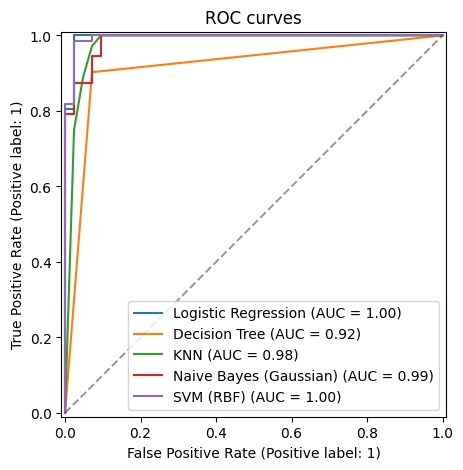

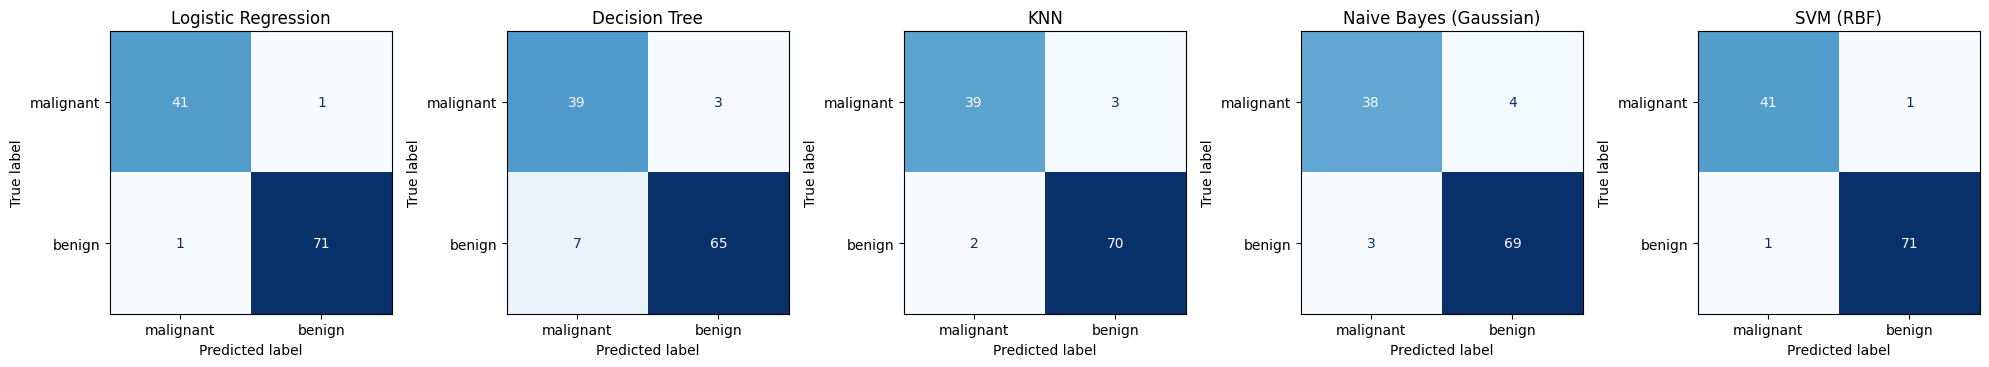

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             ConfusionMatrixDisplay, RocCurveDisplay)

# Dataset: UCI Breast Cancer Wisconsin (569 rows, 30 features, binary)
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(f"Instances: {X.shape[0]} | Features: {X.shape[1]} | Classes: {y.nunique()}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
}

def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

preds, scores, rows = {}, {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    scores[name] = get_scores(model, X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "AUC": roc_auc_score(y_test, scores[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1": f1_score(y_test, preds[name]),
        "MCC": matthews_corrcoef(y_test, preds[name]),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
display(results.style.format("{:.4f}").highlight_max(axis=0, color="lightgreen"))
print("Best model by MCC:", results["MCC"].idxmax())

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name in models:
    RocCurveDisplay.from_predictions(y_test, scores[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves")
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, len(models), figsize=(20, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=data.target_names,
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [2]:
!pip install -q streamlit

In [3]:
%%writefile app.py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             accuracy_score, classification_report, f1_score,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

st.set_page_config(page_title="ML Classification Comparison", layout="wide")
st.title("Classification Model Comparison")
st.caption("Logistic Regression, Decision Tree, KNN, Naive Bayes and SVM, evaluated on one dataset.")


@st.cache_data
def load_builtin():
    data = load_breast_cancer(as_frame=True)
    df = data.frame.copy()
    df["target"] = df["target"].map({0: "malignant", 1: "benign"})
    return df, "target"


def build_models(n_classes):
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Naive Bayes (Gaussian)": GaussianNB(),
        "SVM (RBF)": make_pipeline(
            StandardScaler(), SVC(kernel="rbf", probability=(n_classes > 2), random_state=42)
        ),
    }


def get_scores(model, X, n_classes):
    if hasattr(model, "predict_proba"):
        p = model.predict_proba(X)
        return p[:, 1] if n_classes == 2 else p
    return model.decision_function(X)


@st.cache_data(show_spinner="Training models...")
def run_all(X, y, test_size, seed):
    n_classes = len(np.unique(y))
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )
    avg = "binary" if n_classes == 2 else "weighted"
    rows, outputs = [], {}
    for name, model in build_models(n_classes).items():
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
        score = get_scores(model, X_te, n_classes)
        auc = (roc_auc_score(y_te, score) if n_classes == 2
               else roc_auc_score(y_te, score, multi_class="ovr"))
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "AUC": auc,
            "Precision": precision_score(y_te, pred, average=avg, zero_division=0),
            "Recall": recall_score(y_te, pred, average=avg, zero_division=0),
            "F1": f1_score(y_te, pred, average=avg, zero_division=0),
            "MCC": matthews_corrcoef(y_te, pred),
        })
        outputs[name] = {"pred": pred, "score": score}
    results = pd.DataFrame(rows).set_index("Model")
    return results, outputs, y_te, n_classes


st.sidebar.header("Settings")
source = st.sidebar.radio("Dataset", ["Built-in: Breast Cancer (UCI)", "Upload CSV"])

if source == "Upload CSV":
    file = st.sidebar.file_uploader("CSV file", type="csv")
    if file is None:
        st.info("Upload a CSV with at least 12 features and 500 rows, then pick the target column.")
        st.stop()
    df = pd.read_csv(file)
    target = st.sidebar.selectbox("Target column", df.columns, index=len(df.columns) - 1)
else:
    df, target = load_builtin()

test_size = st.sidebar.slider("Test set size", 0.1, 0.5, 0.2, 0.05)
seed = st.sidebar.number_input("Random seed", value=42, step=1)

df = df.dropna()
X = pd.get_dummies(df.drop(columns=[target]), drop_first=True).astype(float)
label_enc = LabelEncoder()
y = pd.Series(label_enc.fit_transform(df[target]), index=df.index)
class_names = [str(c) for c in label_enc.classes_]

if X.shape[0] < 500 or X.shape[1] < 12:
    st.warning(f"Dataset has {X.shape[0]} rows and {X.shape[1]} features; "
               "the assignment needs at least 500 rows and 12 features.")

results, outputs, y_te, n_classes = run_all(X, y, test_size, int(seed))

tab1, tab2, tab3 = st.tabs(["Metrics comparison", "Model details", "Dataset"])

with tab1:
    st.subheader("Evaluation metrics (test set)")
    st.dataframe(results.style.format("{:.4f}").highlight_max(axis=0, color="#2e7d32"))
    st.caption("Highlighted cell = best model for that metric. "
               + ("" if n_classes == 2 else "Multi-class: weighted precision/recall/F1, one-vs-rest AUC."))
    st.bar_chart(results.drop(columns=["MCC"]).T)
    best = results["MCC"].idxmax()
    st.success(f"Best model by MCC: **{best}** ({results.loc[best, 'MCC']:.4f})")

with tab2:
    model_name = st.selectbox("Select model", list(results.index))
    out = outputs[model_name]
    c1, c2 = st.columns(2)

    with c1:
        st.markdown("**Confusion matrix**")
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay(
            confusion_matrix(y_te, out["pred"]), display_labels=class_names
        ).plot(ax=ax, cmap="Blues", colorbar=False)
        st.pyplot(fig)

    with c2:
        if n_classes == 2:
            st.markdown("**ROC curve**")
            fig, ax = plt.subplots(figsize=(4.5, 4))
            RocCurveDisplay.from_predictions(y_te, out["score"], ax=ax, name=model_name)
            ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
            st.pyplot(fig)
        else:
            st.info("ROC curve is shown for binary problems only.")

    st.markdown("**Classification report**")
    report = classification_report(y_te, out["pred"], target_names=class_names,
                                   output_dict=True, zero_division=0)
    st.dataframe(pd.DataFrame(report).T.round(4))

with tab3:
    st.write(f"**Rows:** {X.shape[0]}  |  **Features:** {X.shape[1]}  |  **Classes:** {n_classes}")
    st.write("**Class distribution**")
    st.bar_chart(df[target].value_counts())
    st.dataframe(df.head(50))

Writing app.py


In [4]:
import os, re, subprocess, time, urllib.request

os.system("pkill -f 'streamlit run'; pkill -f cloudflared")

if not os.path.exists("cloudflared"):
    urllib.request.urlretrieve(
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "cloudflared")
    os.chmod("cloudflared", 0o755)

subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(6)

subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=open("cloudflared.log", "w"), stderr=subprocess.STDOUT)

url = None
for _ in range(40):
    time.sleep(1)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
    if m:
        url = m.group(0)
        break

print("Open your app here:", url if url else "tunnel did not start - see cloudflared.log")

Open your app here: https://nearby-formed-matthew-grow.trycloudflare.com
